<a href="https://colab.research.google.com/github/Lizamn/movie-review-sentiment-analysis/blob/main/NLPproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets nltk
import re, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from datasets import load_dataset
warnings.filterwarnings('ignore')
nltk.download('stopwords', quiet=True)

True

In [ ]:
# IMDb dataset
ds = load_dataset("stanfordnlp/imdb")
train_df = ds['train'].shuffle(seed=42).select(range(5000)).to_pandas()
print(train_df.shape, test_df.shape)
print(train_df['label'].value_counts())
train_df.head()

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

(5000, 2) (2000, 2)
label
1    2506
0    2494
Name: count, dtype: int64


,text,label
0,There is no relation at all between Fortier an...,1
1,This movie is a great. The plot is very true t...,1
2,"George P. Cosmatos' ""Rambo: First Blood Part I...",0
3,In the process of trying to establish the audi...,1
4,"Yeh, I know -- you're quivering with excitemen...",0


In [ ]:
# Preprocessing
stemmer = PorterStemmer()
# keptnegations
stop_words = set(stopwords.words('english')) - {'no', 'not', 'nor', 'never', 'neither'}

def preprocess(text):
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [stemmer.stem(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

train_df['clean'] = train_df['text'].apply(preprocess)
test_df['clean']  = test_df['text'].apply(preprocess)

print("ORIGINAL :", train_df['text'][0][:200])
print("CLEANED  :", train_df['clean'][0][:200])

ORIGINAL : There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. F
CLEANED  : relat fortier profil fact polic seri violent crime profil look crispi fortier look classic profil plot quit simpl fortier plot far complic fortier look like prime suspect spot similar main charact wea


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df['clean'])
X_test  = tfidf.transform(test_df['clean'])
y_train, y_test = train_df['label'], test_df['label']
print("TF-IDF matrix:", X_train.shape)

TF-IDF matrix: (5000, 20000)


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=5),
    "Linear SVM":          LinearSVC(C=0.5),
    "Naive Bayes":         MultinomialNB(alpha=0.5),
    "Random Forest":       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
    "SGD Classifier":      SGDClassifier(loss='modified_huber', alpha=1e-4, random_state=42),
}

results, preds = [], {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1-Score":  f1_score(y_test, y_pred),
        "Train Time (s)": round(train_time, 2),
    })
    print(f"{name:20s} done  | accuracy = {results[-1]['Accuracy']:.4f}")

Logistic Regression  done  | accuracy = 0.8765
Linear SVM           done  | accuracy = 0.8730
Naive Bayes          done  | accuracy = 0.8490
Random Forest        done  | accuracy = 0.8555
SGD Classifier       done  | accuracy = 0.8590


In [ ]:
# Performance table
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df.index += 1
display(results_df.style.format({"Accuracy":"{:.4f}","Precision":"{:.4f}","Recall":"{:.4f}","F1-Score":"{:.4f}"})
        .background_gradient(cmap="Greens", subset=["Accuracy","F1-Score"]))
results_df.to_csv("model_performance.csv")

,Model,Accuracy,Precision,Recall,F1-Score,Train Time (s)
1,Logistic Regression,0.8765,0.8680,0.8880,0.8779,0.740000
2,Linear SVM,0.8730,0.8643,0.8850,0.8745,0.130000
3,SGD Classifier,0.8590,0.8520,0.8690,0.8604,0.040000
4,Random Forest,0.8555,0.8566,0.8540,0.8553,12.060000
5,Naive Bayes,0.8490,0.8525,0.8440,0.8482,0.010000


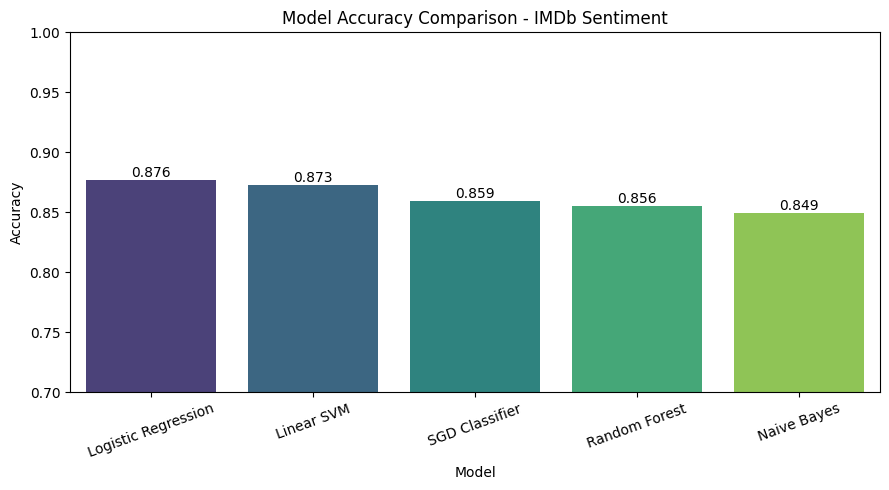

In [ ]:
# Accuracy comparison chart
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=results_df, x="Model", y="Accuracy", palette="viridis")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.ylim(0.7, 1.0)
plt.title("Model Accuracy Comparison - IMDb Sentiment")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=150)
plt.show()

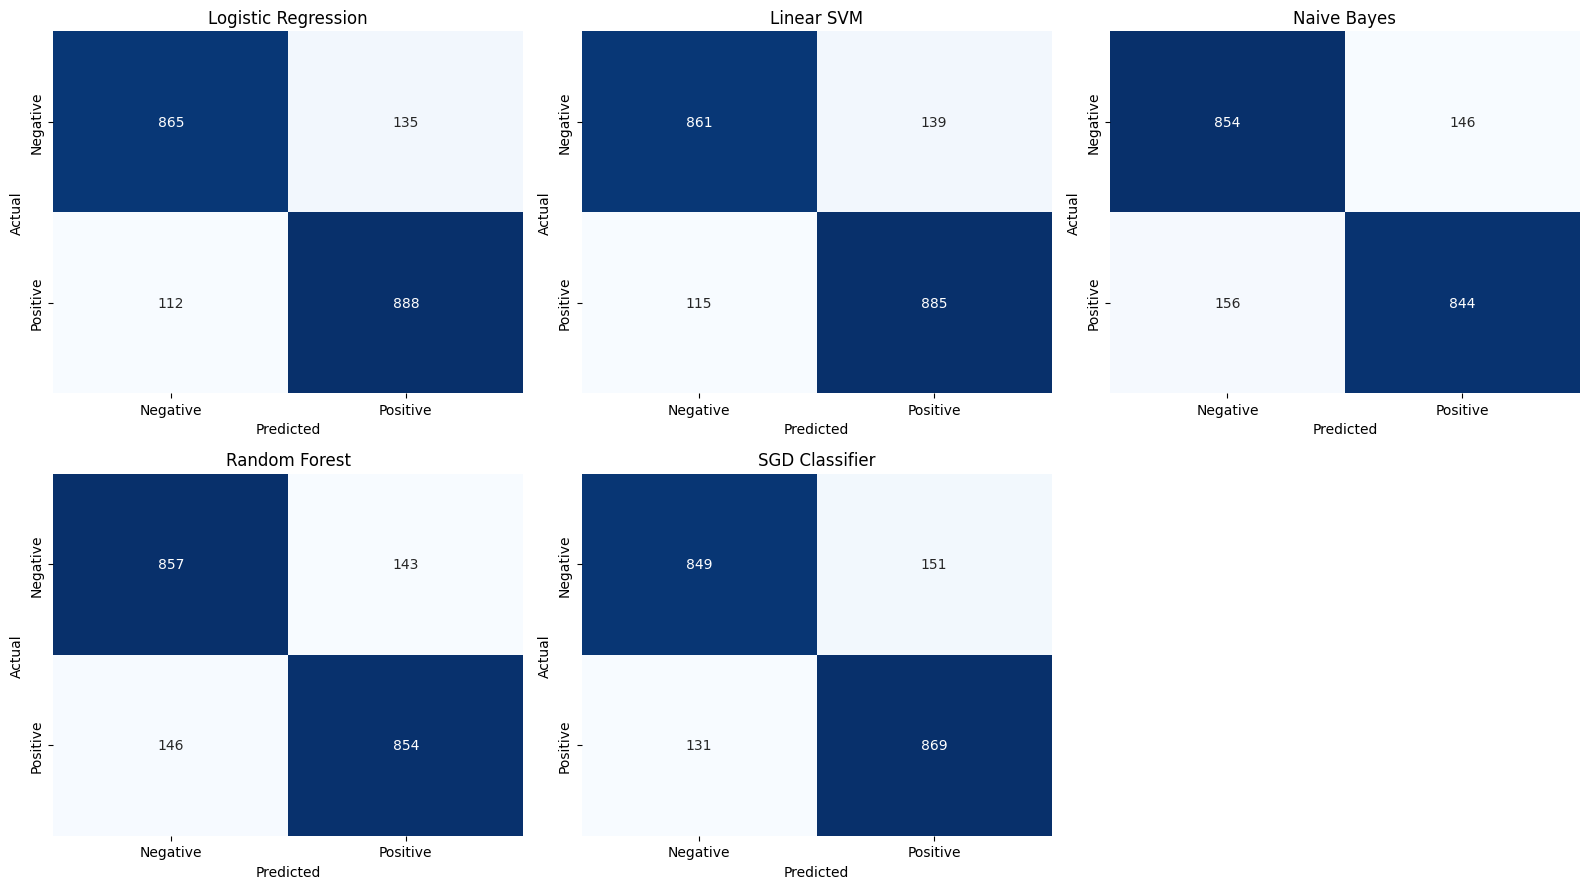

In [ ]:
# Confusion matrix for every model
labels = ["Negative", "Positive"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes[-1].axis('off')
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

In [ ]:
best_name = results_df.loc[1, "Model"]
print("Best model:", best_name)
print(classification_report(y_test, preds[best_name], target_names=labels))

Best model: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.89      0.86      0.88      1000
    Positive       0.87      0.89      0.88      1000

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



predicted_sentiment
Positive    900
Negative    858
Neutral     242
Name: count, dtype: int64


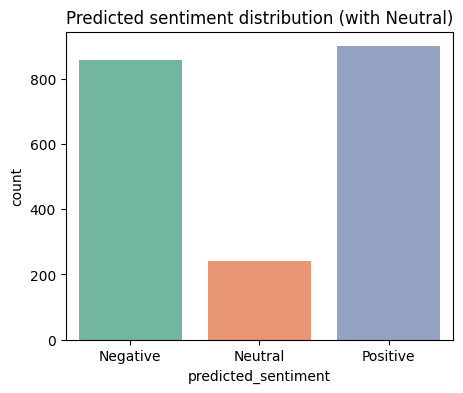

In [ ]:
lr = models["Logistic Regression"]
proba_pos = lr.predict_proba(X_test)[:, 1]

def to_sentiment(p, low=0.40, high=0.60):
    return "Negative" if p < low else ("Positive" if p > high else "Neutral")

test_df['predicted_sentiment'] = [to_sentiment(p) for p in proba_pos]
print(test_df['predicted_sentiment'].value_counts())

plt.figure(figsize=(5,4))
sns.countplot(data=test_df, x='predicted_sentiment', order=["Negative","Neutral","Positive"], palette="Set2")
plt.title("Predicted sentiment distribution (with Neutral)")
plt.show()

In [ ]:
# testing
def predict_review(text):
    p = lr.predict_proba(tfidf.transform([preprocess(text)]))[0, 1]
    return to_sentiment(p), round(p, 3)

for r in ["An absolute masterpiece, brilliant acting and a moving story.",
          "Boring, predictable and a complete waste of time.",
          "It was okay. Some good parts, some bad parts."]:
    print(predict_review(r), "<-", r)

('Positive', np.float64(0.892)) <- An absolute masterpiece, brilliant acting and a moving story.
('Negative', np.float64(0.001)) <- Boring, predictable and a complete waste of time.
('Negative', np.float64(0.199)) <- It was okay. Some good parts, some bad parts.
